# 02 — Análise exploratória (EDA)

Objetivo: responder às hipóteses do `docs/plan.md` a partir da base limpa (`data/processed/clientes_limpo.csv`). Os gráficos são salvos em `docs/img/`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
df = pd.read_csv("../data/processed/clientes_limpo.csv")

print("Shape:", df.shape)

# KPI principal: taxa de resposta da última campanha
print(f"Taxa de resposta geral: {df['Response'].mean():.1%}")

Shape: (2020, 46)
Taxa de resposta geral: 15.3%


### Restaurar tipos e ordem das categorias
O CSV não guarda a ordem das faixas nem o tipo de data. Sem esta etapa, os gráficos mostrariam as faixas em ordem alfabética (ex.: "Até 35" depois de "66+").

In [2]:
ordens = {
    "Faixa_Renda": ["Q1 Baixa", "Q2", "Q3", "Q4 Alta"],
    "Faixa_Etaria": ["Até 35", "36-45", "46-55", "56-65", "66+"],
    "Faixa_Web": ["Baixa (até 20%)", "Média (20-40%)", "Alta (acima de 40%)"],
}
for coluna, ordem in ordens.items():
    df[coluna] = pd.Categorical(df[coluna], categories=ordem, ordered=True)

df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"])

# Conferência: as faixas devem aparecer na ordem lógica
for coluna in ordens:
    print(df[coluna].value_counts(sort=False), "\n")

Faixa_Renda
Q1 Baixa    505
Q2          505
Q3          505
Q4 Alta     505
Name: count, dtype: int64 

Faixa_Etaria
Até 35    430
36-45     687
46-55     435
56-65     401
66+        67
Name: count, dtype: int64 

Faixa_Web
Baixa (até 20%)         271
Média (20-40%)         1244
Alta (acima de 40%)     505
Name: count, dtype: int64 



## Referência da análise
Taxa de resposta geral da última campanha: base de comparação de todos os segmentos. O lift mostra quantas vezes um grupo responde acima (>1) ou abaixo (<1) da média.

In [3]:
taxa_geral = df["Response"].mean()

def taxa_por(coluna):
    """Taxa de resposta, tamanho do grupo e lift para cada categoria da coluna."""
    t = df.groupby(coluna, observed=True)["Response"].agg(taxa="mean", clientes="count")
    t["lift"] = t["taxa"] / taxa_geral
    return t.round(3)

print(f"Taxa geral: {taxa_geral:.1%}")

Taxa geral: 15.3%


## Gráfico 1 — Taxa de aceite por campanha

AcceptedCmp1     0.065
AcceptedCmp2     0.013
AcceptedCmp3     0.075
AcceptedCmp4     0.077
AcceptedCmp5     0.072
Cmp6 (última)    0.153
dtype: float64


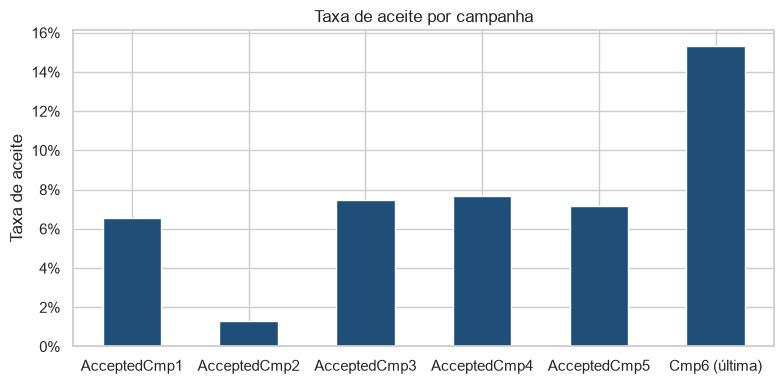

In [4]:
campanhas = ["AcceptedCmp1", "AcceptedCmp2", "AcceptedCmp3",
             "AcceptedCmp4", "AcceptedCmp5", "Response"]
taxas = df[campanhas].mean().rename(index={"Response": "Cmp6 (última)"})
print(taxas.round(3))

ax = taxas.plot(kind="bar", color="#1f4e79", figsize=(8, 4))
ax.set_title("Taxa de aceite por campanha")
ax.set_ylabel("Taxa de aceite")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("../docs/img/01_aceite_por_campanha.png", dpi=150)
plt.show()

**Leitura:** as campanhas 1, 3, 4 e 5 tiveram aceite entre 6,5% e 7,7%. A campanha 2 foi um ponto fora da curva, com só 1,3%. A última campanha (15,3%) dobrou o desempenho das anteriores. A base não informa o que mudou na última campanha (oferta, canal, público), então o salto não pode ser explicado com estes dados, e isso fica registrado como limitação.

## Gráfico 2 — H1 e H7: renda e filhos

              taxa  clientes   lift
Faixa_Renda                        
Q1 Baixa     0.107       505  0.697
Q2           0.123       505  0.800
Q3           0.113       505  0.735
Q4 Alta      0.271       505  1.768 

             taxa  clientes   lift
Tem_Filhos                        
Com filhos  0.105      1455  0.685
Sem filhos  0.278       565  1.811 

Tem_Filhos   Com filhos  Sem filhos
Faixa_Renda                        
Q1 Baixa          0.110       0.094
Q2                0.110       0.256
Q3                0.096       0.195
Q4 Alta           0.103       0.346


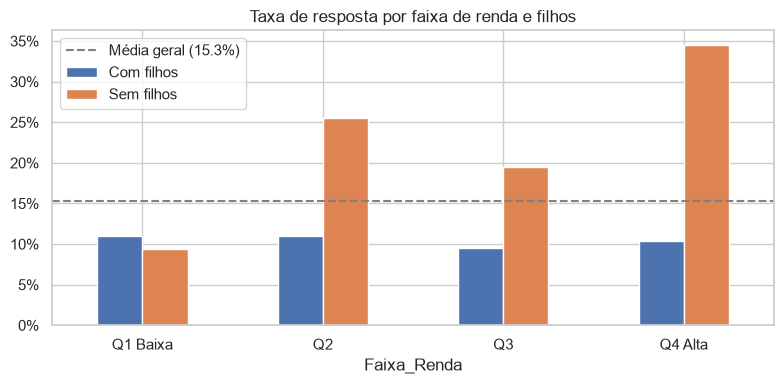

In [5]:
print(taxa_por("Faixa_Renda"), "\n")
print(taxa_por("Tem_Filhos"), "\n")

tabela_h1 = df.pivot_table(values="Response", index="Faixa_Renda",
                           columns="Tem_Filhos", aggfunc="mean", observed=True)
print(tabela_h1.round(3))

ax = tabela_h1.plot(kind="bar", figsize=(8, 4))
ax.axhline(taxa_geral, color="gray", linestyle="--", label=f"Média geral ({taxa_geral:.1%})")
ax.set_title("Taxa de resposta por faixa de renda e filhos")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
ax.legend()
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("../docs/img/02_h1_renda_filhos.png", dpi=150)
plt.show()

**Leitura:**
- **Renda sozinha:** Q1, Q2 e Q3 respondem de forma parecida (10,7% a 12,3%); só o Q4 se destaca, com 27,1% (lift 1,77).
- **Filhos sozinho:** sem filhos responde 27,8% contra 10,5% com filhos (2,6 vezes mais). Com filhos são 72% da base (1.455 clientes).
- **Combinado:** Q4 sem filhos é o melhor público (34,6%, 350 clientes). Com filhos, a taxa fica entre 9,6% e 11% em todos os quartis. Exceção: Q1 sem filhos responde só 9,4%, então não ter filhos só ajuda quando há renda.
- **H1:** confirmada em combinação com ausência de filhos; com a renda sozinha, só o quartil mais alto faz diferença. **H7 (aceite):** clientes com filhos respondem muito menos.

## Gráfico 3 — H2: canal web

               NumWebPurchases  NumCatalogPurchases  NumStorePurchases
Não respondeu             3.94                 2.41               5.76
Respondeu                 5.06                 4.16               6.03 



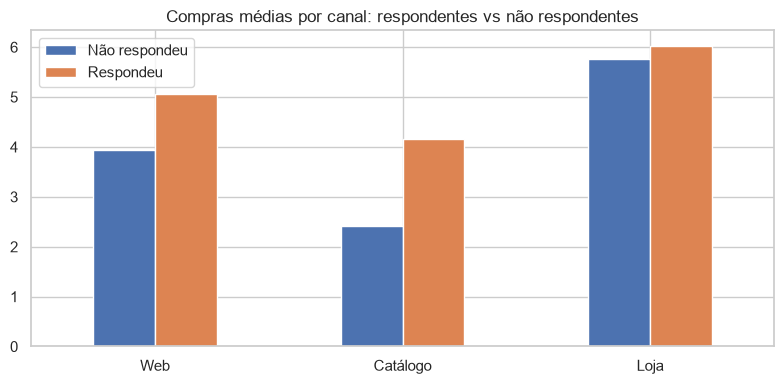

                      taxa  clientes   lift
Faixa_Web                                  
Baixa (até 20%)      0.137       271  0.890
Média (20-40%)       0.146      1244  0.953
Alta (acima de 40%)  0.180       505  1.174


In [6]:
canais = ["NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases"]
mix = df.groupby("Response")[canais].mean()
mix.index = ["Não respondeu", "Respondeu"]
print(mix.round(2), "\n")

ax = mix.T.plot(kind="bar", figsize=(8, 4))
ax.set_title("Compras médias por canal: respondentes vs não respondentes")
ax.set_xticklabels(["Web", "Catálogo", "Loja"], rotation=0)
plt.tight_layout()
plt.savefig("../docs/img/03_h2_canal.png", dpi=150)
plt.show()

# H2 como está no plan.md: taxa de aceite por proporção de compras web
print(taxa_por("Faixa_Web"))

**Leitura:**
- Quem respondeu compra mais em todos os canais, mas a diferença é maior no catálogo (4,16 vs 2,41, +73%) e na web (5,06 vs 3,94, +28%) do que na loja (6,03 vs 5,76, +5%). Respondentes são clientes mais ativos.
- Por proporção de compras web, quem concentra mais de 40% das compras na web responde 18,0% (lift 1,17), contra 13,7% de quem compra pouco pela web.
- O mix agregado do SQL (KPI 3) mostrava a mesma proporção web entre os grupos porque a soma dá mais peso a quem compra muito; a comparação por segmento revela o efeito.
- **H2:** parcialmente confirmada, com efeito moderado. O catálogo é o canal de maior diferença entre quem responde e quem não responde.

## Gráfico 4 — H5: histórico de campanhas

                       mean  count
Campanhas_Anteriores              
0                     0.086   1595
1                     0.312    301
2                     0.514     74
3                     0.800     40
4                     0.900     10 

             taxa  clientes   lift
Ja_Aceitou                        
Não         0.086      1595  0.560
Sim         0.407       425  2.652


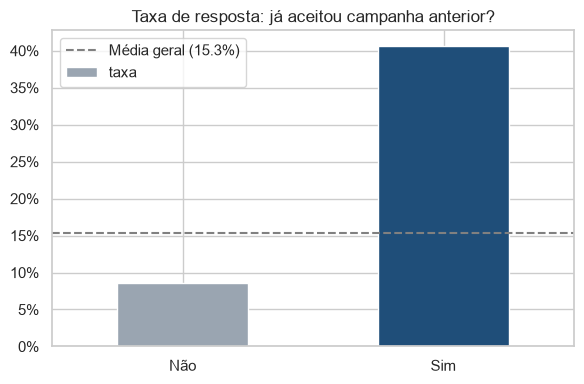

In [7]:
# Detalhe por número de campanhas anteriores aceitas
h5 = df.groupby("Campanhas_Anteriores")["Response"].agg(["mean", "count"])
print(h5.round(3), "\n")

# Resumo: já aceitou alguma vs nunca aceitou
h5_resumo = taxa_por("Ja_Aceitou")
print(h5_resumo)

ax = h5_resumo["taxa"].plot(kind="bar", color=["#9aa5b1", "#1f4e79"], figsize=(6, 4))
ax.axhline(taxa_geral, color="gray", linestyle="--", label=f"Média geral ({taxa_geral:.1%})")
ax.set_title("Taxa de resposta: já aceitou campanha anterior?")
ax.set_xlabel("")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
ax.legend()
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("../docs/img/04_h5_historico.png", dpi=150)
plt.show()

**Leitura:**
- Quem já aceitou alguma campanha anterior responde 40,7%, contra 8,6% de quem nunca aceitou (lift 2,65, 4,7 vezes mais).
- O efeito é de "dose-resposta": 8,6% (nenhuma), 31,2% (1), 51,4% (2), 80% (3) e 90% (4 campanhas aceitas). Os grupos de 3 e 4 campanhas têm só 40 e 10 clientes, mas a tendência é consistente.
- **H5:** confirmada com força. É o preditor mais forte da base.

### H3 — Nunca comprou online

In [8]:
print(taxa_por("Comprou_Online"))

                 taxa  clientes   lift
Comprou_Online                        
Não             0.026        38  0.171
Sim             0.156      1982  1.016


**Leitura:** quem nunca comprou online responde 2,6% (lift 0,17), contra 15,6% de quem já comprou. Porém são só 38 clientes (1,9% da base). **H3:** confirmada na direção, com impacto prático pequeno: excluir esse público reduz pouco o custo da campanha.

### H4 — Idade

In [9]:
print(taxa_por("Faixa_Etaria"), "\n")
print(df.groupby("Faixa_Etaria", observed=True)[["Pct_Web", "NumWebVisitsMonth"]].mean().round(2))

               taxa  clientes   lift
Faixa_Etaria                        
Até 35        0.188       430  1.227
36-45         0.147       687  0.958
46-55         0.126       435  0.824
56-65         0.152       401  0.991
66+           0.179        67  1.167 

              Pct_Web  NumWebVisitsMonth
Faixa_Etaria                            
Até 35           0.32               5.52
36-45            0.34               5.60
46-55            0.33               5.20
56-65            0.33               4.98
66+              0.31               3.75


**Leitura:**
- No total, a resposta por idade forma um "U": Até 35 com 18,8% (lift 1,23), 46-55 com 12,6% (lift 0,82) e 66+ com 17,9% (só 67 clientes).
- O comportamento digital quase não muda com a idade: a proporção de compras web fica entre 31% e 34% em todas as faixas. As visitas ao site são parecidas até 65 anos (cerca de 5 a 5,6 por mês) e caem no 66+ (3,75).
- **H4:** não confirmada na parte digital; a parte de aceite é explicada pelos filhos (ver cruzamento idade × filhos).

### H6, H7 e H8 — Consumo por renda, filhos e estado civil

In [10]:
for coluna in ["Faixa_Renda", "Tem_Filhos", "Estado_Civil"]:
    print(df.groupby(coluna, observed=True)[["Gasto_Total", "Ticket_Medio"]].mean().round(0), "\n")

print(taxa_por("Estado_Civil"))

             Gasto_Total  Ticket_Medio
Faixa_Renda                           
Q1 Baixa            84.0          13.0
Q2                 233.0          21.0
Q3                 753.0          43.0
Q4 Alta           1367.0          73.0 

            Gasto_Total  Ticket_Medio
Tem_Filhos                           
Com filhos        408.0          28.0
Sem filhos       1126.0          63.0 

              Gasto_Total  Ticket_Medio
Estado_Civil                           
Mora junto          600.0          37.0
Mora sozinho        626.0          39.0 

               taxa  clientes   lift
Estado_Civil                        
Mora junto    0.113      1298  0.738
Mora sozinho  0.226       722  1.471


**Leitura:**
- **Renda:** o gasto cresce em todos os quartis (84 → 233 → 753 → 1.367), e o ticket médio também (13 → 21 → 43 → 73). **H6:** confirmada com força.
- **Filhos:** clientes sem filhos gastam 1.126, contra 408 de quem tem filhos (2,8 vezes mais), com ticket de 63 contra 28. **H7 (consumo):** não confirmada; o resultado é o oposto do esperado.
- **Estado civil:** quem mora junto gasta 600 e quem mora sozinho, 626: praticamente igual. **H8:** não confirmada.
- **Achado novo:** apesar de gastar o mesmo, quem mora sozinho responde o dobro às campanhas (22,6% contra 11,3%, lift 1,47). Possível efeito dos filhos, já que quem mora sozinho tende a ter menos filhos; a investigar.
- **Insight central:** o público sem filhos é, ao mesmo tempo, o que mais responde e o que mais gasta. Direcionar a campanha para ele aumenta a conversão e o valor gerado.

### H9 — Categorias compradas juntas
Correlação entre as categorias de gasto: de 0 (sem relação) a 1 (andam juntas).

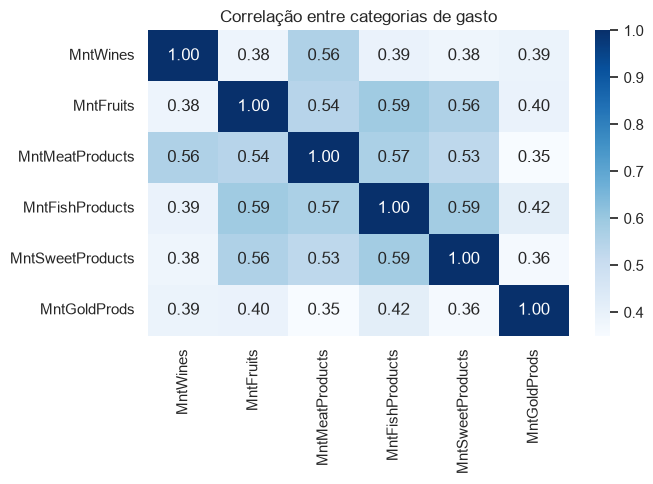

In [11]:
cols_gasto = ["MntWines", "MntFruits", "MntMeatProducts",
              "MntFishProducts", "MntSweetProducts", "MntGoldProds"]
corr = df[cols_gasto].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="Blues")
plt.title("Correlação entre categorias de gasto")
plt.tight_layout()
plt.savefig("../docs/img/05_h9_cesta.png", dpi=150)
plt.show()

In [12]:
# Jovens respondem mais por serem jovens ou por terem menos filhos?
print(pd.crosstab(df["Faixa_Etaria"], df["Tem_Filhos"], normalize="index").round(2), "\n")
print(df.pivot_table(values="Response", index="Faixa_Etaria",
                     columns="Tem_Filhos", aggfunc="mean", observed=True).round(3))

Tem_Filhos    Com filhos  Sem filhos
Faixa_Etaria                        
Até 35              0.61        0.39
36-45               0.82        0.18
46-55               0.75        0.25
56-65               0.71        0.29
66+                 0.21        0.79 

Tem_Filhos    Com filhos  Sem filhos
Faixa_Etaria                        
Até 35             0.114       0.307
36-45              0.114       0.298
46-55              0.082       0.262
56-65              0.108       0.261
66+                0.071       0.208


**Leitura:**
- As correlações entre categorias são moderadas (0,35 a 0,59). Os pares mais fortes são frutas e peixe (0,59), peixe e doces (0,59), carne e peixe (0,57) e vinho e carne (0,56).
- Frutas, peixe, doces e carne formam um grupo que anda junto; produtos premium (gold) são a categoria mais independente.
- **Ressalva:** clientes que gastam muito gastam mais em tudo, o que infla as correlações. Elas indicam afinidade entre categorias, mas não provam compra conjunta no mesmo pedido.
- **H9:** parcialmente confirmada. Candidatos a promoção casada: vinho + carne e peixe + frutas/doces.

# Parte B — KPIs oficiais em SQL
As queries ficam em `sql/kpis.sql`, que é o registro oficial dos cálculos. Estes números são o gabarito para conferir o dashboard.

In [13]:
import duckdb, os
os.chdir("..")  # roda a partir da raiz, para os caminhos do .sql funcionarem

with open("sql/kpis.sql", encoding="utf-8") as f:
    queries = [q.strip() for q in f.read().split(";") if q.strip()]

for q in queries:
    print(q.splitlines()[0])        # imprime o comentário com o nome do KPI
    print(duckdb.sql(q).df(), "\n")

-- KPI 1: Taxa de resposta geral
   total_clientes  responderam  taxa_resposta_pct
0            2020        310.0              15.35 

-- KPI 2: Taxa de resposta por faixa de renda e filhos (H1, H7)
  Faixa_Renda  Tem_Filhos  clientes  taxa_resposta_pct
0    Q1 Baixa  Com filhos       420              10.95
1    Q1 Baixa  Sem filhos        85               9.41
2          Q2  Com filhos       462              11.04
3          Q2  Sem filhos        43              25.58
4          Q3  Com filhos       418               9.57
5          Q3  Sem filhos        87              19.54
6     Q4 Alta  Com filhos       155              10.32
7     Q4 Alta  Sem filhos       350              34.57 

-- KPI 3: Mix de canal por resposta (H2)
   Response  pct_web  pct_catalogo  pct_loja
0         0     32.5          19.9      47.6
1         1     33.2          27.3      39.6 

-- KPI 4: Resposta por histórico de campanhas (H5)
  Ja_Aceitou  clientes  taxa_resposta_pct
0        Não      1595           

### Leitura dos KPIs (SQL)

**Reconciliação:** SQL e Python batem: 2.020 clientes, 310 responderam, taxa de 15,35%.

**H1 e H7 — Renda e filhos (KPI 2)**
- O maior público de resposta é **Q4 Alta sem filhos: 34,6%**, mais que o dobro da média, num grupo de 350 clientes.
- Clientes **com filhos** respondem entre 9,6% e 11% em **todos** os quartis: a renda só faz diferença para quem não tem filhos.
- **H1:** confirmada em combinação com ausência de filhos; parcial considerando só a renda.
- Q2 sem filhos (25,6%) tem só 43 clientes e não sustenta conclusão.

**H2 — Canal web (KPI 3)**
- No mix agregado, a proporção web é igual entre quem respondeu (33,2%) e quem não respondeu (32,5%), e o catálogo se destaca (27,3% vs 19,9%).
- Porém, comparando por segmento (Gráfico 3), clientes com mais de 40% das compras na web respondem 18,0% (lift 1,17). O agregado escondia o efeito por dar mais peso a quem compra muito.
- **H2:** parcialmente confirmada, com efeito moderado; o catálogo é o diferencial mais forte.

**H3 — Nunca comprou online (KPI 7)**
- Quem nunca comprou online responde **2,6%** (lift 0,17), contra 15,6% de quem já comprou.
- Porém são só **38 clientes** (1,9% da base), com apenas 1 resposta.
- **H3:** confirmada na direção, mas com impacto prático pequeno: excluir esse público reduz pouco o custo da campanha.

**H4 — Idade (KPI 8 + cruzamento com filhos)**
- No total, o padrão é em "U": Até 35 com 18,8% (lift 1,23), 46-55 com 12,6% (lift 0,82) e 66+ com 17,9%.
- Separando por filhos, o efeito quase desaparece: entre clientes sem filhos, a resposta fica entre 26% e 31% em todas as idades. O "U" era efeito da composição: Até 35 e 66+ têm mais clientes sem filhos.
- O 66+ é um paradoxo de Simpson: menor taxa dentro de cada grupo, mas acima da média no total.
- **H4:** não confirmada como efeito próprio da idade. Resta só um leve efeito da juventude entre os clientes sem filhos (cerca de 4 a 5 pontos).

**H5 — Histórico de aceite (KPI 4 e KPI 6)**
- Quem já aceitou alguma campanha responde **40,7%**, contra 8,6% de quem nunca aceitou: **4,7 vezes mais**, num grupo de 425 clientes.
- **H5:** confirmada com força.
- Porém, dos 310 respondentes da última campanha, **137 (44%) nunca tinham aceitado antes**: o histórico é o melhor preditor, mas não deve ser o único critério de seleção.

**H6 — Renda e valor do cliente (KPI 5)**
- O gasto cresce em todos os quartis: **84 → 233 → 753 → 1.367**. O Q4 gasta cerca de 16 vezes mais que o Q1.
- O ticket médio acompanha: **13,2 → 21,2 → 43,1 → 73,1**.
- O maior salto está entre Q2 e Q3 (gasto mais que triplica).
- **H6:** confirmada com força.

**Engajamento (KPI 6)**
- **27,8% da base** (562 clientes) já aceitou ao menos uma das 6 campanhas.

### Síntese preliminar

**Ter ou não ter filhos é a variável que mais separa quem responde:** clientes sem filhos respondem cerca de 3 vezes mais que clientes com filhos, em qualquer faixa de renda ou idade, e também gastam 2,8 vezes mais.

**Público prioritário da próxima campanha:** clientes sem filhos, de renda alta (Q4, acima de 68.462) e com histórico de aceite. É, ao mesmo tempo, o público que mais responde e o que mais gera receita.

**Canal:** catálogo é o canal de maior diferença entre quem responde e quem não responde; a web tem efeito moderado.

**O que não se confirmou:** idade (efeito explicado pelos filhos), consumo maior de clientes com filhos (é o oposto) e consumo maior de casados (é igual).

**Limitações:** a base não tem custo por campanha nem explica por que a última campanha dobrou a taxa de aceite.

**Leitura — idade vs filhos:**
- A proporção de clientes sem filhos varia muito por faixa: 39% em Até 35, 18% em 36-45 e 79% em 66+.
- Separando por filhos, a resposta quase não varia com a idade: sem filhos fica entre 26% e 31%; com filhos, entre 7% e 11%. A diferença entre ter e não ter filhos é de cerca de 3 vezes em todas as faixas.
- O padrão em "U" do KPI 8 era, em grande parte, efeito da composição: as faixas Até 35 e 66+ responderam mais porque têm mais clientes sem filhos.
- O caso 66+ é um paradoxo de Simpson: tem a menor taxa dentro de cada grupo (7,1% e 20,8%), mas aparecia acima da média no total por ter 79% de clientes sem filhos.
- Resta um leve efeito da juventude entre os clientes sem filhos (30,7% em Até 35 contra 26,1% em 56-65).
- **Conclusão:** filhos é a variável dominante; a idade tem efeito pequeno.

### Síntese preliminar

**Ter ou não ter filhos é a variável que mais separa quem responde:** clientes sem filhos respondem cerca de 3 vezes mais que clientes com filhos, em qualquer faixa de renda ou de idade.

O público prioritário da próxima campanha combina **ausência de filhos, renda alta e histórico de aceite**, com o **catálogo** como canal de maior diferença. A idade, que parecia relevante, tem efeito pequeno quando se controla por filhos. Clientes com filhos respondem pouco em qualquer segmento.